# Experiment 8: Multilingual Abstractive Text Summarization (mT5 vs. mBART)

This notebook implements and evaluates abstractive text summarization on the **Hindi** split of the **XL-Sum (Cross-Lingual Summarization)** dataset (`csebuetnlp/xlsum`) using two multilingual Transformer sequence-to-sequence models:
1. **mT5** (`Anshugh/mt5-small-hindi-xlsum` — Multilingual Text-to-Text Transfer Transformer fine-tuned on Hindi XL-Sum)
2. **mBART** (`ai4bharat/IndicBART-XLSum` — Multilingual `MBartForConditionalGeneration` architecture fine-tuned on XL-Sum)

Both models are compared using **ROUGE-1**, **ROUGE-2**, **ROUGE-L** (with a Unicode-aware tokenizer for Devanagari script), and **mBERTScore** (`bert-base-multilingual-cased`).

## 1. Load the XL-Sum Hindi Dataset

We load the downloaded Hindi test split (`hindi/test/0000.parquet`) from `csebuetnlp/xlsum` and select 20 diverse articles for evaluation on CPU.

In [1]:
import re
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

df = pd.read_parquet("hindi/test/0000.parquet")
print(f"Total Hindi XL-Sum test articles: {len(df)}")
print("Columns:", df.columns.tolist())

# Select 20 articles with substantial text for evaluation
df_eval = df[df["text"].str.len() > 300].iloc[:20].reset_index(drop=True)
articles = df_eval["text"].tolist()
references = df_eval["summary"].tolist()

print(f"Evaluation sample size: {len(articles)} articles")
print("\nSample Article Title:", df_eval.loc[0, "title"])
print("Sample Reference Summary:", references[0])

Using device: cpu
Total Hindi XL-Sum test articles: 8847
Columns: ['id', 'url', 'title', 'summary', 'text']
Evaluation sample size: 20 articles

Sample Article Title: साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट
Sample Reference Summary: मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.


## 2. Model 1 — mT5 (`Anshugh/mt5-small-hindi-xlsum`)

We load the fine-tuned mT5-small Hindi XL-Sum model and generate abstractive summaries using beam search (`num_beams=4`, `max_new_tokens=80`).

In [2]:
MT5_MODEL = "Anshugh/mt5-small-hindi-xlsum"
mt5_tokenizer = AutoTokenizer.from_pretrained(MT5_MODEL)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(MT5_MODEL).to(device)
mt5_model.eval()

def generate_mt5_summaries(texts, batch_size=4):
    preds = []
    t0 = time.time()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = ["summarize: " + t for t in texts[i:i + batch_size]]
            enc = mt5_tokenizer(
                batch, max_length=512, truncation=True, padding=True, return_tensors="pt"
            ).to(device)
            out_ids = mt5_model.generate(
                **enc, max_new_tokens=80, num_beams=4, no_repeat_ngram_size=3, early_stopping=True
            )
            preds.extend(mt5_tokenizer.batch_decode(out_ids, skip_special_tokens=True))
    return preds, time.time() - t0

mt5_summaries, mt5_time = generate_mt5_summaries(articles)
print(f"mT5 generated {len(mt5_summaries)} summaries in {mt5_time:.2f}s")
print("mT5 Sample Summary [0]:", mt5_summaries[0])

mT5 generated 20 summaries in 30.49s
mT5 Sample Summary [0]: महाराष्ट्र पुलिस ने मालेगाँव और सूरत के मोडासा ज़िले में हुए धमाकों के सिलसिले में पुलिस हिरासत में रखने का आदेश दिया है.


## 3. Model 2 — mBART (`ai4bharat/IndicBART-XLSum`)

We load `ai4bharat/IndicBART-XLSum` (an `MBartForConditionalGeneration` model trained on XL-Sum across Indic languages). Hindi inputs use the `<2hi>` language token (`<s> ... </s> <2hi>`), with `decoder_start_token_id` set to `<2hi>`.

In [3]:
import sentencepiece as spm

MBART_MODEL = "ai4bharat/IndicBART-XLSum"
mbart_tokenizer = AutoTokenizer.from_pretrained(
    MBART_MODEL, do_lower_case=False, use_fast=False, keep_accents=True
)
mbart_sp = spm.SentencePieceProcessor(model_file=mbart_tokenizer.vocab_file)
mbart_model = AutoModelForSeq2SeqLM.from_pretrained(MBART_MODEL).to(device)
mbart_model.eval()

hi_id = mbart_tokenizer.convert_tokens_to_ids("<2hi>")
bos_id = mbart_tokenizer.bos_token_id
eos_id = mbart_tokenizer.eos_token_id
pad_id = mbart_tokenizer.pad_token_id

def encode_indicbart(texts, max_len=512):
    seqs = [mbart_sp.encode(t[:1500], out_type=int)[:max_len - 2] + [eos_id, hi_id] for t in texts]
    max_b = max(len(s) for s in seqs)
    input_ids = torch.full((len(seqs), max_b), pad_id, dtype=torch.long)
    attn_mask = torch.zeros((len(seqs), max_b), dtype=torch.long)
    for idx, s in enumerate(seqs):
        input_ids[idx, :len(s)] = torch.tensor(s, dtype=torch.long)
        attn_mask[idx, :len(s)] = 1
    return {"input_ids": input_ids.to(device), "attention_mask": attn_mask.to(device)}

def decode_indicbart(out_ids):
    sp_size = mbart_sp.get_piece_size()
    results = []
    for seq in out_ids.tolist():
        valid = [tok_id for tok_id in seq if 3 < tok_id < sp_size]
        results.append(mbart_sp.decode(valid).strip())
    return results

def generate_mbart_summaries(texts, batch_size=4):
    preds = []
    t0 = time.time()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = encode_indicbart(texts[i:i + batch_size], max_len=512)
            out_ids = mbart_model.generate(
                **enc,
                max_new_tokens=80,
                num_beams=4,
                no_repeat_ngram_size=3,
                early_stopping=True,
                decoder_start_token_id=hi_id,
                bos_token_id=bos_id,
                eos_token_id=eos_id,
            )
            preds.extend(decode_indicbart(out_ids))
    return preds, time.time() - t0

mbart_summaries, mbart_time = generate_mbart_summaries(articles)
print(f"mBART (IndicBART-XLSum) generated {len(mbart_summaries)} summaries in {mbart_time:.2f}s")
print("mBART Sample Summary [0]:", mbart_summaries[0])

mBART (IndicBART-XLSum) generated 20 summaries in 54.25s
mBART Sample Summary [0]: साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक पुलिस हिरासत में रखने का आदेश- नासिक की अदालत ने कहा- मध्य प्रदेश में हुए धमाका और सूरत के मोडासा में हुई धमाकों के सिलसिले में पूछताछ की जा रही है. बीबीसी संवाददाता रेहाना बस्तीवाला - कोर्ट ने कहा प्रेस रिव्यू वीडियो


## 4. Automatic Evaluation: ROUGE-1, ROUGE-2, ROUGE-L & mBERTScore

Because the default `rouge_score` tokenizer strips non-ASCII characters, we supply a Unicode word tokenizer (`re.findall(r"\w+", text, flags=re.UNICODE)`) so Devanagari tokens are scored accurately. For semantic similarity, we compute **mBERTScore** using `bert-base-multilingual-cased`.

In [4]:
class UnicodeTokenizer:
    """Unicode-aware tokenizer for Devanagari / multilingual ROUGE scoring."""
    def tokenize(self, text):
        # Match contiguous Devanagari / Unicode word characters including matras
        cleaned = re.sub(r"[।,!?;:()\[\]\-]+", " ", text.strip())
        return cleaned.split()

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=False,
    tokenizer=UnicodeTokenizer(),
)

def evaluate_summaries(model_name, preds, refs, elapsed_sec):
    r1, r2, rl = [], [], []
    for pred, ref in zip(preds, refs):
        sc = scorer.score(ref, pred)
        r1.append(sc["rouge1"].fmeasure)
        r2.append(sc["rouge2"].fmeasure)
        rl.append(sc["rougeL"].fmeasure)

    P, R, F1 = bert_score_fn(
        preds, refs, model_type="bert-base-multilingual-cased", lang="hi", verbose=False
    )

    return {
        "ROUGE-1": float(np.mean(r1)),
        "ROUGE-2": float(np.mean(r2)),
        "ROUGE-L": float(np.mean(rl)),
        "mBERTScore-P": float(P.mean().item()),
        "mBERTScore-R": float(R.mean().item()),
        "mBERTScore-F1": float(F1.mean().item()),
        "Time (s)": elapsed_sec,
    }

mt5_metrics = evaluate_summaries("mT5", mt5_summaries, references, mt5_time)
mbart_metrics = evaluate_summaries("mBART (IndicBART-XLSum)", mbart_summaries, references, mbart_time)

comp_df = pd.DataFrame({
    "mT5 (mt5-small-hindi-xlsum)": mt5_metrics,
    "mBART (IndicBART-XLSum)": mbart_metrics,
}).T

print("=== Multilingual Summarization Evaluation (XL-Sum Hindi, N=20) ===")
print(comp_df.round(4).to_string())

=== Multilingual Summarization Evaluation (XL-Sum Hindi, N=20) ===
                             ROUGE-1  ROUGE-2  ROUGE-L  mBERTScore-P  mBERTScore-R  mBERTScore-F1  Time (s)
mT5 (mt5-small-hindi-xlsum)   0.2770   0.1151   0.2325        0.7443        0.7207         0.7321   30.4880
mBART (IndicBART-XLSum)       0.2034   0.0617   0.1456        0.6742        0.7013         0.6871   54.2519


## 5. Qualitative Comparison & Visualization

We display sample generated summaries side-by-side with the gold reference summaries and plot the ROUGE and mBERTScore comparison.

--- Example 1: साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट ---
Reference: मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.
mT5:       महाराष्ट्र पुलिस ने मालेगाँव और सूरत के मोडासा ज़िले में हुए धमाकों के सिलसिले में पुलिस हिरासत में रखने का आदेश दिया है.
mBART:     साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक पुलिस हिरासत में रखने का आदेश- नासिक की अदालत ने कहा- मध्य प्रदेश में हुए धमाका और सूरत के मोडासा में हुई धमाकों के सिलसिले में पूछताछ की जा रही है. बीबीसी संवाददाता रेहाना बस्तीवाला - कोर्ट ने कहा प्रेस रिव्यू वीडियो

--- Example 2: मुशर्रफ़ का पर्चा मंज़ूर, प्रदर्शनों पर लाठी ---
Reference: पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रपति चुनाव के उम्मीदवारों के नामांकन पत्रों की जाँच - पड़ताल के मौक़े पर इस्लामाबाद में आयोग की इमारत के सामने वकीलों और राजनीतिक कार्यकर्ताओं के प्रदर्शन पर पुलिस ने लाठी चार्ज किया है जिसमें अनेक लोग घायल हो गए.
mT5:       पाकिस

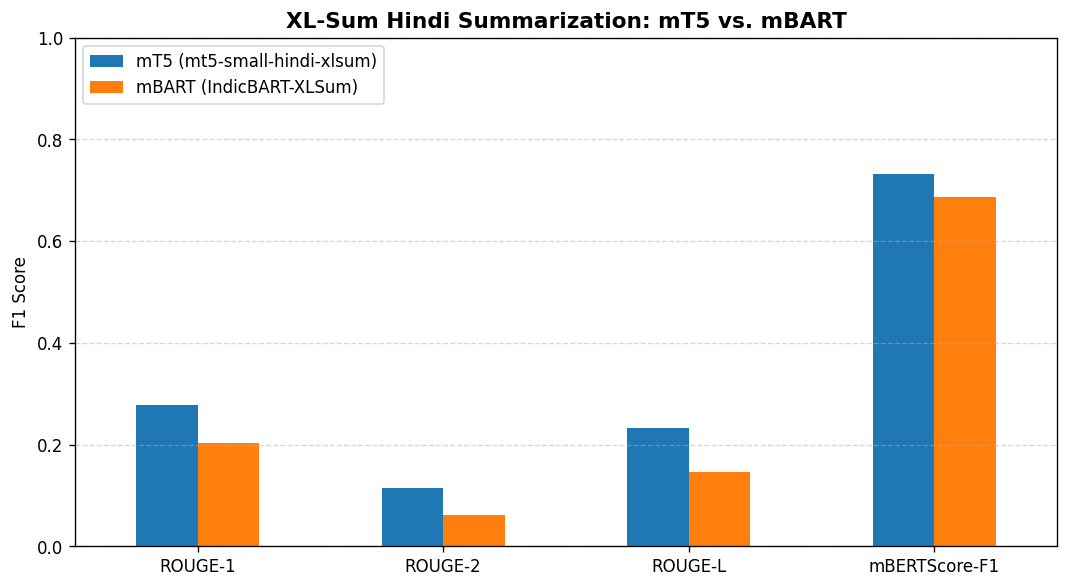

In [5]:
for idx in range(3):
    print(f"--- Example {idx + 1}: {df_eval.loc[idx, 'title']} ---")
    print("Reference:", references[idx])
    print("mT5:      ", mt5_summaries[idx])
    print("mBART:    ", mbart_summaries[idx])
    print()

# Comparative Bar Chart
metrics_cols = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERTScore-F1"]
fig, ax = plt.subplots(figsize=(9, 5))
comp_df[metrics_cols].T.plot(kind="bar", ax=ax, rot=0, ylim=(0, 1.0))
ax.set_title("XL-Sum Hindi Summarization: mT5 vs. mBART", fontsize=13, fontweight="bold")
ax.set_ylabel("F1 Score")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()